# Mini-DrawBench
Runtime: T4 GPU. Data is saved to Drive, so any cell can be re-run after a disconnect.

## Setup

In [3]:
!python generate.py --help

usage: generate.py [-h] [--models MODELS [MODELS ...]]
                   [--seeds SEEDS [SEEDS ...]] [--ids [IDS ...]]

options:
  -h, --help            show this help message and exit
  --models MODELS [MODELS ...]
                        sdxl_turbo, sd15
  --seeds SEEDS [SEEDS ...]
  --ids [IDS ...]       Subset of prompt ids (default: all)


In [1]:
REPO_URL = "https://github.com/HarshadaDhawade/MSAI-630-Residency.git"
DATA_DIR = "/content/drive/MyDrive/mini-drawbench-data"

import os
from google.colab import drive
drive.mount("/content/drive")
os.environ["MDB_DATA"] = DATA_DIR
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists("/content/mini-drawbench"):
    !git clone -q {REPO_URL} /content/mini-drawbench
%cd /content/mini-drawbench
!git pull -q

Mounted at /content/drive
/content/mini-drawbench


In [2]:
!pip install -q -r requirements.txt
!pip uninstall -y -q torchao
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## Generate

In [9]:
!python generate.py --models sdxl_turbo sd15 --seeds 42

[sdxl_turbo] 47 images to generate
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...:   0% 0/7 [00:00<?, ?it/s]
Loading weights:   0% 0/517 [00:00<?, ?it/s]
Loading weights:  17% 90/517 [00:00<00:00, 859.11it/s]
Loading weights:  34% 176/517 [00:00<00:00, 833.18it/s]
Loading weights:  50% 260/517 [00:00<00:00, 811.88it/s]
Loading weights:  66% 342/517 [00:00<00:00, 780.30it/s]
Loading weights:  81% 421/517 [00:00<00:00, 781.04it/s]
Loading weights: 100% 517/517 [00:00<00:00, 806.13it/s]
Loadi

In [10]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/mini-drawbench-data")

sdxl_images = list((data_dir / "images/sdxl_turbo").glob("*.png"))
sd15_images = list((data_dir / "images/sd15").glob("*.png"))

print("SDXL-Turbo images:", len(sdxl_images))
print("Stable Diffusion 1.5 images:", len(sd15_images))
print("Total images:", len(sdxl_images) + len(sd15_images))

SDXL-Turbo images: 48
Stable Diffusion 1.5 images: 48
Total images: 96


In [8]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/mini-drawbench-data")

images = list(data_dir.rglob("*.png"))

print("Total images found:", len(images))

for img in images:
    print(img)

Total images found: 2
/content/drive/MyDrive/mini-drawbench-data/images/sdxl_turbo/C01_s42.png
/content/drive/MyDrive/mini-drawbench-data/images/sd15/C01_s42.png


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Project locations
data_dir = Path("/content/drive/MyDrive/mini-drawbench-data")
project_dir = Path("/content/mini-drawbench")

# Load prompts and generated image results
prompts_df = pd.read_csv(project_dir / "prompts.csv")
results_df = pd.read_csv(data_dir / "generations.csv")

# Inspect available columns
print("Prompt columns:", prompts_df.columns.tolist())
print("Result columns:", results_df.columns.tolist())

display(prompts_df.head(2))
display(results_df.head(2))

Prompt columns: ['id', 'category', 'prompt', 'checklist']
Result columns: ['model', 'prompt_id', 'category', 'seed', 'status', 'path', 'seconds', 'info', 'timestamp']


,id,category,prompt,checklist
0,C01,counting,Exactly four red apples on a white plate,exactly 4 apples; the apples are red; a white ...
1,C02,counting,Three cats sitting on a sofa,exactly 3 cats; a sofa; cats are sitting on it


,model,prompt_id,category,seed,status,path,seconds,info,timestamp
0,sdxl_turbo,C01,counting,42,ok,images/sdxl_turbo/C01_s42.png,4.59,steps=4;cfg=0.0,2026-10-23T23:45:52+00:00
1,sd15,C01,counting,42,ok,images/sd15/C01_s42.png,4.85,steps=25;cfg=7.5,2026-10-23T23:47:01+00:00


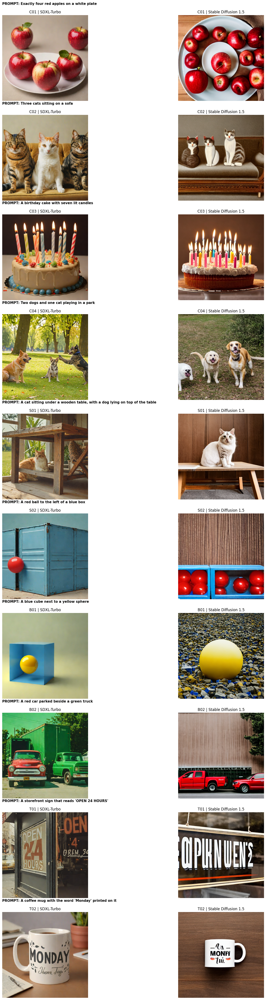

In [16]:
import matplotlib.pyplot as plt
from PIL import Image

# Select 10 prompt IDs from the dataset
prompt_ids = [
    "C01", "C02", "C03", "C04",
    "S01", "S02",
    "B01", "B02",
    "T01", "T02"
]

fig, axes = plt.subplots(10, 2, figsize=(14, 45))

for row, prompt_id in enumerate(prompt_ids):

    # Find the original prompt
    prompt_row = prompts_df[
        prompts_df["id"].astype(str) == prompt_id
    ]

    if prompt_row.empty:
        print(f"Prompt {prompt_id} not found")
        continue

    prompt_text = prompt_row.iloc[0]["prompt"]

    # Image paths
    sdxl_path = data_dir / f"images/sdxl_turbo/{prompt_id}_s42.png"
    sd15_path = data_dir / f"images/sd15/{prompt_id}_s42.png"

    # Display SDXL-Turbo
    axes[row, 0].imshow(Image.open(sdxl_path))
    axes[row, 0].set_title(
        f"{prompt_id} | SDXL-Turbo",
        fontsize=12
    )
    axes[row, 0].axis("off")

    # Display Stable Diffusion 1.5
    axes[row, 1].imshow(Image.open(sd15_path))
    axes[row, 1].set_title(
        f"{prompt_id} | Stable Diffusion 1.5",
        fontsize=12
    )
    axes[row, 1].axis("off")

    # Show prompt above each pair
    axes[row, 0].text(
        0, 1.12,
        f"PROMPT: {prompt_text}",
        transform=axes[row, 0].transAxes,
        fontsize=11,
        fontweight="bold",
        wrap=True
    )

plt.tight_layout()
plt.show()

## CLIP scores

In [11]:
!python score_clip.py

96 images to score with ViT-H-14:laion2b_s32b_b79k

open_clip_model.safetensors: downloading bytes:   5% 192M/3.94G [00:01<00:14, 258MB/s, 14.8MB/s  ]
open_clip_model.safetensors: downloading bytes:   7% 288M/3.94G [00:01<00:12, 296MB/s, 23.3MB/s  ]
open_clip_model.safetensors: downloading bytes:   9% 371M/3.94G [00:02<00:15, 227MB/s, 31.5MB/s  ]
open_clip_model.safetensors: downloading bytes:  14% 564M/3.94G [00:02<00:12, 280MB/s, 47.9MB/s  ]
open_clip_model.safetensors: downloading bytes:  33% 1.31G/3.94G [00:05<00:10, 257MB/s,  102MB/s  ]
open_clip_model.safetensors: downloading bytes:  35% 1.39G/3.94G [00:08<00:52, 48.7MB/s, 81.9MB/s  ]
open_clip_model.safetensors: reconstructing file:  36% 1.41G/3.94G [00:11<00:17, 142MB/s, 29.2MB/s  ]
open_clip_model.safetensors: downloading bytes:  47% 1.85G/3.94G [00:12<00:07, 273MB/s, 90.4MB/s  ]
open_clip_model.safetensors: downloading bytes:  48% 1.89G/3.94G [00:12<00:08, 247MB/s, 93.6MB/s  ]
open_clip_model.safetensors: downloading bytes:  

In [19]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/mini-drawbench-data")

print("Searching for CLIP evaluation files...\n")

for file in data_dir.rglob("*"):
    if file.is_file():
        print(file.relative_to(data_dir))

Searching for CLIP evaluation files...

generations.csv
clip_scores.csv
images/sdxl_turbo/C01_s42.png
images/sdxl_turbo/C02_s42.png
images/sdxl_turbo/C03_s42.png
images/sdxl_turbo/C04_s42.png
images/sdxl_turbo/C05_s42.png
images/sdxl_turbo/C06_s42.png
images/sdxl_turbo/C07_s42.png
images/sdxl_turbo/C08_s42.png
images/sdxl_turbo/S01_s42.png
images/sdxl_turbo/S02_s42.png
images/sdxl_turbo/S03_s42.png
images/sdxl_turbo/S04_s42.png
images/sdxl_turbo/S05_s42.png
images/sdxl_turbo/S06_s42.png
images/sdxl_turbo/S07_s42.png
images/sdxl_turbo/S08_s42.png
images/sdxl_turbo/B01_s42.png
images/sdxl_turbo/B02_s42.png
images/sdxl_turbo/B03_s42.png
images/sdxl_turbo/B04_s42.png
images/sdxl_turbo/B05_s42.png
images/sdxl_turbo/B06_s42.png
images/sdxl_turbo/B07_s42.png
images/sdxl_turbo/B08_s42.png
images/sdxl_turbo/T01_s42.png
images/sdxl_turbo/T02_s42.png
images/sdxl_turbo/T03_s42.png
images/sdxl_turbo/T04_s42.png
images/sdxl_turbo/T05_s42.png
images/sdxl_turbo/T06_s42.png
images/sdxl_turbo/T07_s42.pn

In [21]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/mini-drawbench-data")

print("Evaluation files:\n")

for file in data_dir.rglob("*"):
    if file.is_file() and file.suffix.lower() != ".png":
        print(file.relative_to(data_dir))


Evaluation files:

generations.csv
clip_scores.csv


In [22]:
import pandas as pd
from pathlib import Path

# Location of your project data
data_dir = Path("/content/drive/MyDrive/mini-drawbench-data")

# Load CLIP evaluation results
clip_df = pd.read_csv(data_dir / "clip_scores.csv")

print("Total CLIP records:", len(clip_df))

print("\nAvailable columns:")
print(clip_df.columns.tolist())

print("\nFirst 20 CLIP results:")
display(clip_df.head(20))

Total CLIP records: 96

Available columns:
['scorer', 'key', 'model', 'prompt_id', 'category', 'seed', 'clip_cos', 'clip_score']

First 20 CLIP results:


,scorer,key,model,prompt_id,category,seed,clip_cos,clip_score
0,ViT-H-14:laion2b_s32b_b79k,sd15/B01_s42,sd15,B01,color_binding,42,0.36367,36.367
1,ViT-H-14:laion2b_s32b_b79k,sd15/B02_s42,sd15,B02,color_binding,42,0.35959,35.959
2,ViT-H-14:laion2b_s32b_b79k,sd15/B03_s42,sd15,B03,color_binding,42,0.38746,38.746
3,ViT-H-14:laion2b_s32b_b79k,sd15/B04_s42,sd15,B04,color_binding,42,0.36375,36.375
4,ViT-H-14:laion2b_s32b_b79k,sd15/B05_s42,sd15,B05,color_binding,42,0.26764,26.764
5,ViT-H-14:laion2b_s32b_b79k,sd15/B06_s42,sd15,B06,color_binding,42,0.35635,35.635
6,ViT-H-14:laion2b_s32b_b79k,sd15/B07_s42,sd15,B07,color_binding,42,0.39805,39.805
7,ViT-H-14:laion2b_s32b_b79k,sd15/B08_s42,sd15,B08,color_binding,42,0.32427,32.427
8,ViT-H-14:laion2b_s32b_b79k,sd15/C01_s42,sd15,C01,counting,42,0.34413,34.413
9,ViT-H-14:laion2b_s32b_b79k,sd15/C02_s42,sd15,C02,counting,42,0.38895,38.895


In [23]:
# Compare CLIP scores between the two models

model_comparison = (
    clip_df.groupby("model")["clip_score"]
    .agg(["mean", "std", "min", "max", "count"])
    .round(3)
)

print("Mini-DrawBench: CLIP Performance Comparison")

display(model_comparison)

Mini-DrawBench: CLIP Performance Comparison


,mean,std,min,max,count
model,,,,,
sd15,32.629,5.406,20.974,44.532,48
sdxl_turbo,37.287,4.560,25.938,46.905,48


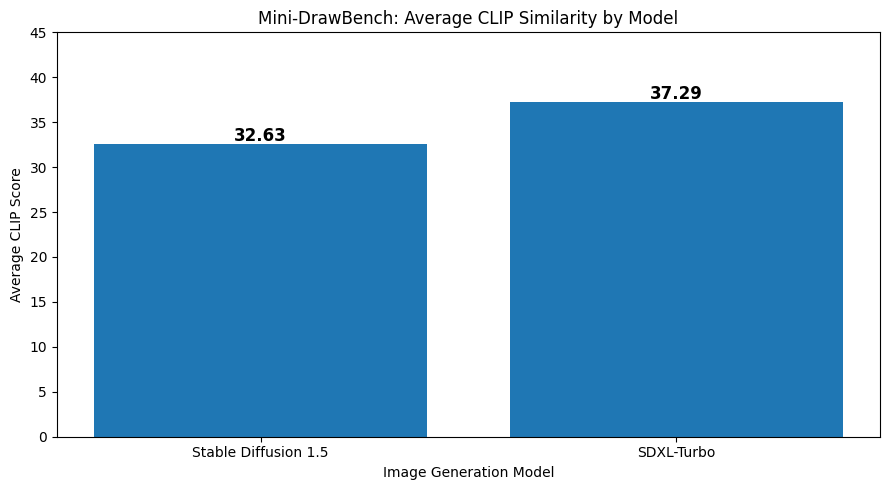

In [24]:
import matplotlib.pyplot as plt

# Average CLIP scores
average_scores = clip_df.groupby("model")["clip_score"].mean()

# Create chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    ["Stable Diffusion 1.5", "SDXL-Turbo"],
    [average_scores["sd15"], average_scores["sdxl_turbo"]]
)

# Display values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.3,
        f"{height:.2f}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title("Mini-DrawBench: Average CLIP Similarity by Model")
plt.xlabel("Image Generation Model")
plt.ylabel("Average CLIP Score")
plt.ylim(0, 45)

plt.tight_layout()

# Save chart to Google Drive
plt.savefig(data_dir / "clip_model_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate average CLIP score for each category and model
category_comparison = (
    clip_df
    .groupby(["category", "model"])["clip_score"]
    .mean()
    .unstack()
    .round(2)
)

# Rename model columns for readability
category_comparison = category_comparison.rename(
    columns={
        "sd15": "Stable Diffusion 1.5",
        "sdxl_turbo": "SDXL-Turbo"
    }
)

# Format category names
category_comparison.index = (
    category_comparison.index
    .str.replace("_", " ")
    .str.title()
)

print("Mini-DrawBench: Category-wise CLIP Comparison")
display(category_comparison)

Mini-DrawBench: Category-wise CLIP Comparison


model,Stable Diffusion 1.5,SDXL-Turbo
category,,
Color Binding,35.26,39.79
Conflicting,30.95,34.01
Counting,32.14,37.68
Rare Words,35.23,37.49
Spatial,32.30,35.29
Text Rendering,29.90,39.47


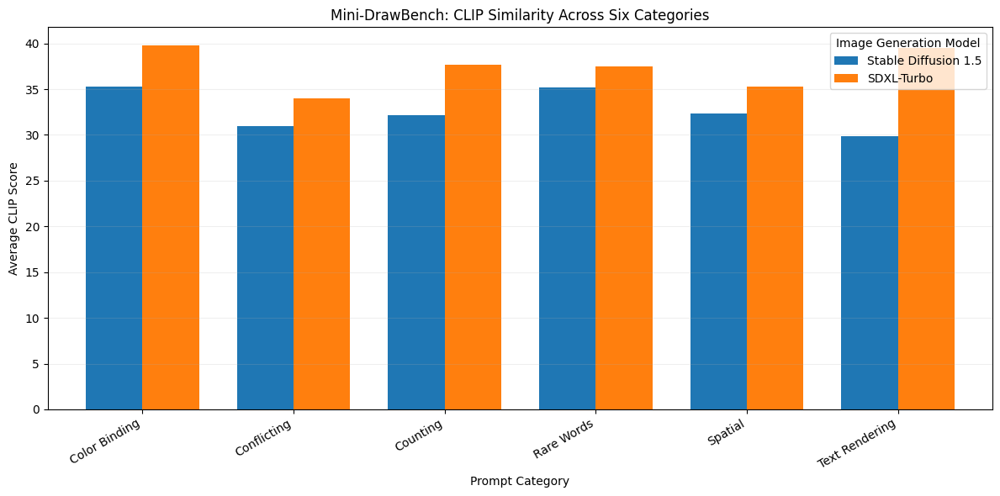

In [26]:
# Create a grouped bar chart
ax = category_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("Mini-DrawBench: CLIP Similarity Across Six Categories")
plt.xlabel("Prompt Category")
plt.ylabel("Average CLIP Score")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Image Generation Model")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save chart to Google Drive
plt.savefig(
    data_dir / "clip_category_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Human ratings
Share the gradio.live link with the team. Stop the cell once every image has 2 ratings.

In [27]:
!python rate_app.py --share

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://29fb09e083983e8dcd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/queueing.py", line 848, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/route_utils.py", line 417, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<12 lines>...
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2698, in process_api
    result = await self.call_function(
         

In [30]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/mini-drawbench-data")

for file in data_dir.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".csv", ".json", ".jsonl", ".db", ".sqlite"]:
        print(file.relative_to(data_dir))

generations.csv
clip_scores.csv
ratings.csv


In [31]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/mini-drawbench-data")

print("Saved evaluation files:\n")

for file in data_dir.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".csv", ".json", ".jsonl", ".db", ".sqlite"]:
        print(file.relative_to(data_dir), "|", file.stat().st_size, "bytes")

Saved evaluation files:

generations.csv | 10138 bytes
clip_scores.csv | 8254 bytes
ratings.csv | 22538 bytes


In [32]:
import pandas as pd

ratings_df = pd.read_csv(data_dir / "ratings.csv")

print("Total human rating records:", len(ratings_df))

print("\nAvailable columns:")
print(ratings_df.columns.tolist())

print("\nFirst 5 ratings:")
display(ratings_df.head())

Total human rating records: 192

Available columns:
['timestamp', 'rater', 'key', 'model', 'prompt_id', 'category', 'seed', 'items_passed', 'n_items', 'n_passed', 'all_pass', 'overall', 'broken', 'notes']

First 5 ratings:


,timestamp,rater,key,model,prompt_id,category,seed,items_passed,n_items,n_passed,all_pass,overall,broken,notes
0,2026-10-24T00:21:22+00:00,harshada,sdxl_turbo/C02_s42,sdxl_turbo,C02,counting,42,"[true, true, true]",3,3,0,3,1,NaN
1,2026-10-24T00:21:46+00:00,harshada,sd15/B07_s42,sd15,B07,color_binding,42,"[true, true, true]",3,3,1,3,0,NaN
2,2026-10-24T00:22:14+00:00,harshada,sdxl_turbo/S07_s42,sdxl_turbo,S07,spatial,42,"[true, false, true]",3,2,0,2,0,NaN
3,2026-10-24T00:23:34+00:00,harshada,sdxl_turbo/B04_s42,sdxl_turbo,B04,color_binding,42,"[false, false, false]",3,0,0,2,0,The animal's eyes are not prominent enough
4,2026-10-24T00:25:20+00:00,harshada,sd15/C08_s42,sd15,C08,counting,42,"[false, false]",2,0,0,2,0,The image does not follow the prompt accuratel...


In [33]:
# Check how many ratings each evaluator submitted
print("Ratings by evaluator:")
display(ratings_df["rater"].value_counts())

# Verify that every image received two ratings
ratings_per_image = ratings_df.groupby("key")["rater"].nunique()

print("\nImages with exactly 2 different evaluators:",
      (ratings_per_image == 2).sum())

print("Total unique images rated:", len(ratings_per_image))

# Calculate average human rating for each model
human_comparison = (
    ratings_df.groupby("model")["overall"]
    .agg(["mean", "std", "count"])
    .round(3)
)

print("\nAverage human evaluation scores:")
display(human_comparison)

Ratings by evaluator:


,count
rater,
harshada,96
patrick,96



Images with exactly 2 different evaluators: 96
Total unique images rated: 96

Average human evaluation scores:


,mean,std,count
model,,,
sd15,2.927,1.069,96
sdxl_turbo,3.490,1.005,96


In [34]:
import pandas as pd

# Average the two human ratings for each image
human_avg = (
    ratings_df
    .groupby(["key", "model", "prompt_id", "category"])["overall"]
    .mean()
    .reset_index()
    .rename(columns={"overall": "human_avg"})
)

# Combine human ratings with CLIP scores
comparison_df = pd.merge(
    clip_df,
    human_avg,
    on=["key", "model", "prompt_id", "category"],
    how="inner"
)

print("Total images compared:", len(comparison_df))

display(
    comparison_df[
        ["model", "prompt_id", "category", "clip_score", "human_avg"]
    ].head(10)
)

Total images compared: 96


,model,prompt_id,category,clip_score,human_avg
0,sd15,B01,color_binding,36.367,2.5
1,sd15,B02,color_binding,35.959,2.5
2,sd15,B03,color_binding,38.746,3.0
3,sd15,B04,color_binding,36.375,3.5
4,sd15,B05,color_binding,26.764,1.5
5,sd15,B06,color_binding,35.635,1.5
6,sd15,B07,color_binding,39.805,3.5
7,sd15,B08,color_binding,32.427,2.5
8,sd15,C01,counting,34.413,3.5
9,sd15,C02,counting,38.895,3.5


In [35]:
# Calculate agreement between CLIP and human ratings
correlation = comparison_df[
    ["clip_score", "human_avg"]
].corr(method="spearman")

print("CLIP vs Human Rating Correlation:")
display(correlation)

print(
    "\nSpearman correlation:",
    round(correlation.loc["clip_score", "human_avg"], 3)
)

CLIP vs Human Rating Correlation:


,clip_score,human_avg
clip_score,1.00000,0.52897
human_avg,0.52897,1.00000



Spearman correlation: 0.529


In [36]:
# Calculate Spearman correlation
correlation = comparison_df[
    ["clip_score", "human_avg"]
].corr(method="spearman")

spearman_score = correlation.loc[
    "clip_score", "human_avg"
]

print("Mini-DrawBench: CLIP vs Human Evaluation")
print("-------------------------------------")
print("Total images evaluated:", len(comparison_df))
print("Spearman correlation:", round(spearman_score, 3))

display(correlation)

# Calculate correlation separately for each model
print("\nCorrelation by model:")

for model, group in comparison_df.groupby("model"):
    score = group["clip_score"].corr(
        group["human_avg"],
        method="spearman"
    )

    print(model, ":", round(score, 3))

Mini-DrawBench: CLIP vs Human Evaluation
-------------------------------------
Total images evaluated: 96
Spearman correlation: 0.529


,clip_score,human_avg
clip_score,1.00000,0.52897
human_avg,0.52897,1.00000



Correlation by model:
sd15 : 0.68
sdxl_turbo : 0.211


In [38]:
# Calculate percentile ranks within each model
comparison_df["clip_rank"] = (
    comparison_df.groupby("model")["clip_score"]
    .rank(pct=True)
)

comparison_df["human_rank"] = (
    comparison_df.groupby("model")["human_avg"]
    .rank(pct=True)
)

# Positive = CLIP ranks the image higher than humans do
comparison_df["rank_gap"] = (
    comparison_df["clip_rank"] - comparison_df["human_rank"]
)

# Largest disagreements
disagreements = (
    comparison_df
    .assign(abs_gap=lambda df: df["rank_gap"].abs())
    .sort_values("abs_gap", ascending=False)
)

print("Top 10 CLIP–Human Disagreements:")

display(
    disagreements[
        [
            "model",
            "prompt_id",
            "category",
            "clip_score",
            "human_avg",
            "rank_gap"
        ]
    ].head(10).round(3)
)

Top 10 CLIP–Human Disagreements:


,model,prompt_id,category,clip_score,human_avg,rank_gap
84,sdxl_turbo,T05,text_rendering,41.794,2.5,0.771
51,sdxl_turbo,B04,color_binding,40.721,2.0,0.708
94,sdxl_turbo,X07,conflicting,31.921,4.5,-0.708
76,sdxl_turbo,S05,spatial,32.526,4.5,-0.688
67,sdxl_turbo,R04,rare_words,35.430,5.0,-0.677
91,sdxl_turbo,X04,conflicting,33.960,4.5,-0.646
48,sdxl_turbo,B01,color_binding,43.690,3.0,0.625
16,sd15,R01,rare_words,31.071,4.5,-0.615
82,sdxl_turbo,T03,text_rendering,43.052,3.0,0.604
5,sd15,B06,color_binding,35.635,1.5,0.604


## Analysis

# Mini-DrawBench results

CLIP scorer: `ViT-H-14:laion2b_s32b_b79k`

Images scored: 96 · images with human ratings: 96 · ratings: 192 · raters: 2

Refusals by model: {}


## Headline numbers

- Spearman ρ, CLIP vs human overall (all images): **0.53**
- AUC, CLIP predicting a human pass (0.5 = coin flip): **0.73**
- Within-prompt concordance (CLIP orders image pairs like humans): **77%** over 26 pairs
- CLIP picks the same winning model as humans: **75%** of 40 prompt-level comparisons
- 'CLIP fooled' images (top-quartile CLIP, failed by humans): **11**
- 'CLIP too harsh' images (bottom-quartile CLIP, passed by humans): **3**

## Human pass rate by model and category

| category       | sd15   | sdxl_turbo   |
|:---------------|:-------|:-------------|
| counting       | 12%    | 12%          |
| spatial        | 19%    | 44%          |
| color_binding  | 19%    | 12%          |
| text_rendering | 0%     | 19%          |
| rare_words     | 38%    | 56%          |
| conflicting    | 19% 

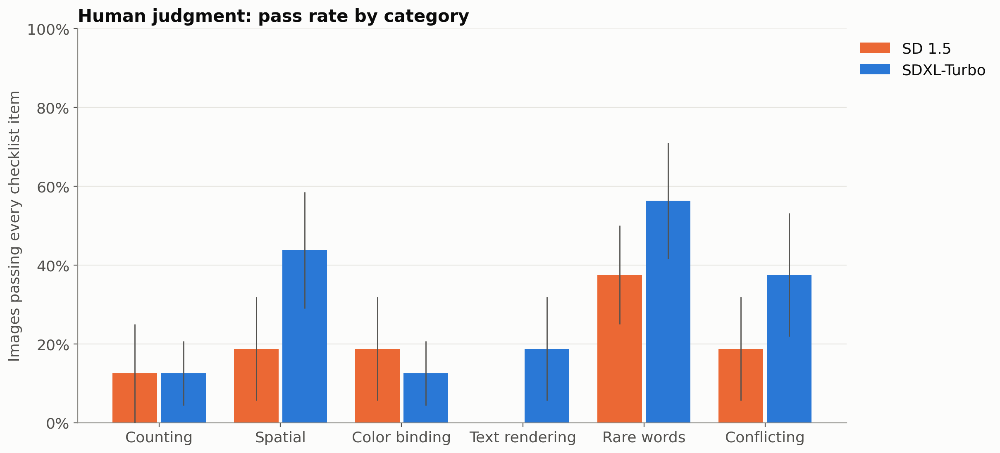

fig2_clip_by_category.png


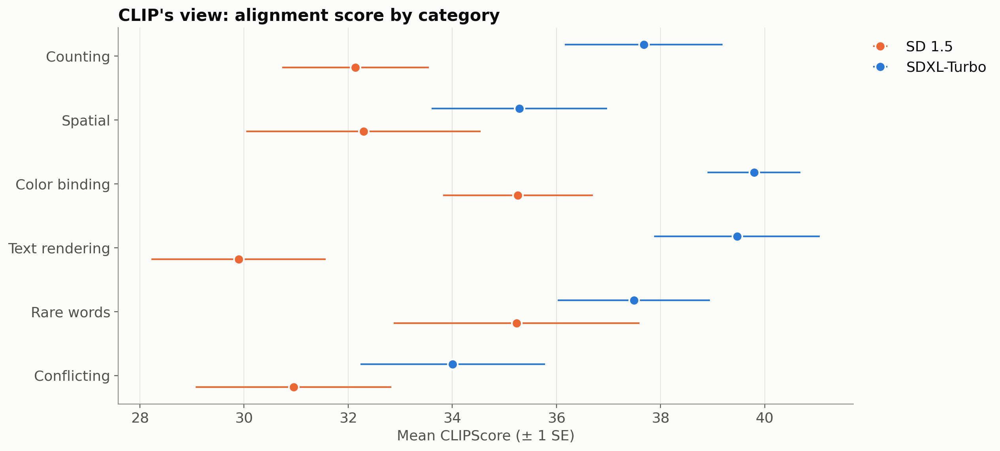

fig3_clip_vs_human.png


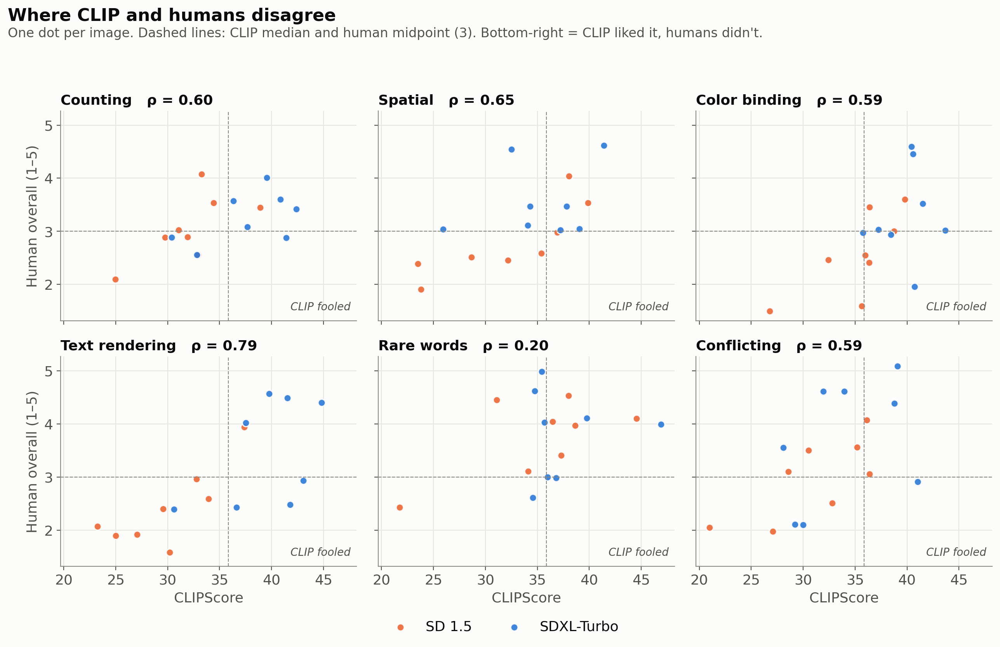

fig4_clip_agreement_by_category.png


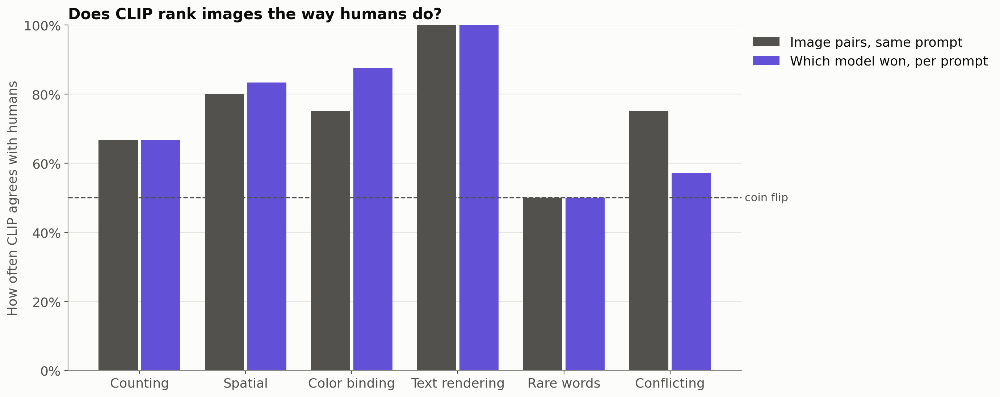

fig5_failure_gallery.png


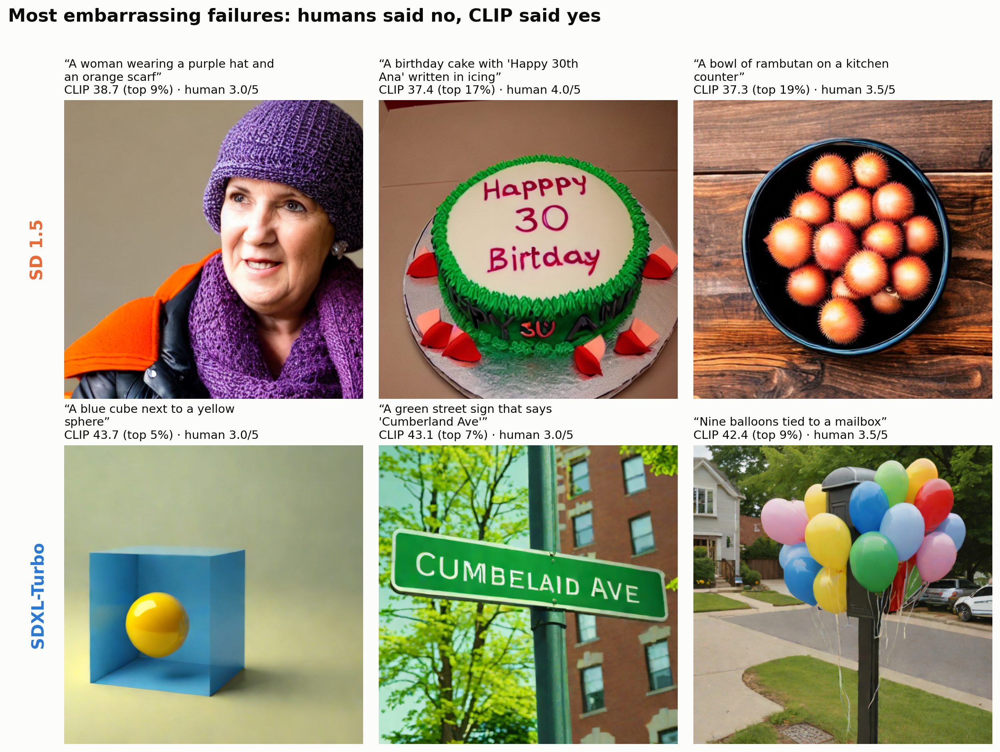

In [39]:
!python analyze.py

import glob
from PIL import Image
for f in sorted(glob.glob(f"{DATA_DIR}/results/fig*.png")):
    print(os.path.basename(f))
    display(Image.open(f))

## Diversity

In [40]:
!python diversity.py --models sdxl_turbo sd15
!python diversity.py --models sd15 --guidance 2 5 7.5 12

for f in sorted(glob.glob(f"{DATA_DIR}/results/fig[67]*.png")):
    print(os.path.basename(f))
    display(Image.open(f))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...:  29% 2/7 [00:01<00:03,  1.28it/s]
Loading weights:   0% 0/517 [00:00<?, ?it/s]
Loading weights:  10% 51/517 [00:00<00:00, 485.29it/s]
Loading weights:  21% 110/517 [00:00<00:00, 466.23it/s]
Loading weights:  36% 184/517 [00:00<00:00, 579.21it/s]
Loading weights:  49% 253/517 [00:00<00:00, 611.27it/s]
Loading weights:  64% 331/517 [00:00<00:00, 657.87it/s]
Loading weights:  77% 398/517 [00:00<00:00, 579.45it/s]
Loading weights: 100% 517/517 [0

## Demo

In [ ]:
!python demo_app.py --share

## Export results

In [ ]:
!cd {DATA_DIR} && zip -qr /content/mini-drawbench-results.zip results generations.csv clip_scores.csv ratings.csv
from google.colab import files
files.download("/content/mini-drawbench-results.zip")